# Hof Lecture | Descriptive Analytics: Supply Chain KPIs
**Instructor solution: target changes applied, worked answers included.**

**Business question:** How do transport choices and service targets change the performance we report?

After this lab, you can calculate and compare lead time, simplified OTIF, average cost, mode share and cost share; explain a percentage-point difference; and separate a reporting change from a physical improvement.

**Hands-on sequence:** Complete the baseline analysis, then Experiments 1, 2, 3, 4 and 5 in order. For each experiment, inspect BEFORE, make the marked CHANGE, inspect AFTER and answer THINK before continuing. Complete the five matching Pingo questions after the hands-on activities.

Run from top to bottom. Edit only `# <-- CHANGE HERE` lines. Each experiment independently starts from the original baseline. Run the cell once before changing its parameter, then rerun it after your change.

**KPI convention:** actual OTIF requires delivery on time AND in full. Completeness is not modeled here. Our classroom OTIF is an on-time approximation: `On_Time = LeadTime_days <= SLA_days`; `OTIF` is an identical Boolean alias used for the classroom KPI. `OTIF (%) = 100 × mean(OTIF)`.

The scenarios summarize synthetic data and hypothetical transformations. They do not establish real-world causal effects or optimal transport decisions.


## Dataset and measures
We generate 600 shipments using seed 42. One row is one simplified warehouse-to-customer transport leg, assigned a single mode. These are stylized comparable legs, not a realistic complete Asia–Europe network.

| Column | Meaning / unit |
|---|---|
| Shipment_ID | Unique shipment identifier |
| Transport_Mode | Road, Air, Sea; Rail only in Experiment 5 |
| Distance_km | Simulated leg distance in km |
| Cost_EUR | Transport cost per shipment in EUR |
| LeadTime_days | Simulated elapsed lead time in calendar days |
| SLA_days | Promised maximum elapsed duration in calendar days |
| On_Time | True when lead time is no greater than SLA |
| OTIF | Classroom alias for On_Time; no completeness data |

| Mode | Cost rate (EUR/km) | Base lead time (days) | SLA (days) |
|---|---:|---:|---:|
| Road | 1.00 | 5.0 | 6 |
| Air | 2.00 | 2.5 | 3 |
| Sea | 0.50 | 18.0 | 20 |
| Rail | 0.80 | 8.0 | 10 |

Lead time also includes a distance term and random variation; the base is not the realized average. Sea uses a larger distance term. Costs include an initial random multiplier from 0.9 to 1.1. All scenarios retain these original notebook assumptions.

**Mode share (%)** = mode shipment count / total count × 100. **Cost share (%)** = mode total cost / all-shipment total cost × 100. Cost share reflects volume as well as cost per shipment.

**Signed difference** = AFTER − BEFORE, calculated before rounding. OTIF differences use **percentage points**. A positive difference means an increase, which need not be favorable. Displayed values use two decimals.


## Teacher setup — run, no edits needed

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

In [2]:
# TEACHER-PROVIDED FUNCTIONS — RUN THIS CELL; NO NEED TO EDIT.
MODE_COST = {"Road": 1.0, "Air": 2.0, "Sea": 0.5, "Rail": 0.8}
MODE_LEAD = {"Road": 5.0, "Air": 2.5, "Sea": 18.0, "Rail": 8.0}
MODE_SLA = {"Road": 6, "Air": 3, "Sea": 20, "Rail": 10}

def simulate_shipments(n=600, shares=None, seed=42, rail_settings=None):
    """Make reproducible synthetic shipments from transport-mode shares."""
    if shares is None:
        shares = {"Road": 0.60, "Air": 0.15, "Sea": 0.25}
    if any(v < 0 for v in shares.values()) or not np.isclose(sum(shares.values()), 1):
        raise ValueError("Transport shares must be nonnegative and add to 1.0")
    r = np.random.default_rng(seed)
    modes = r.choice(list(shares), size=n, p=list(shares.values()))
    dist = np.round(np.clip(r.normal(800, 300, n), 50, 5000), 0)
    rates = np.array([MODE_COST[m] for m in modes], dtype=float)
    bases = np.array([MODE_LEAD[m] for m in modes], dtype=float)
    slas = np.array([MODE_SLA[m] for m in modes], dtype=int)
    if rail_settings is not None:
        rates[modes == "Rail"] = rail_settings["cost_per_km"]
        bases[modes == "Rail"] = rail_settings["base_lead_time"]
        slas[modes == "Rail"] = rail_settings["sla_days"]
    cost = np.round(dist * rates * r.uniform(0.9, 1.1, n), 2)
    lead = np.round(np.clip(bases + dist / 1000 * np.where(modes == "Sea", 4, 1) + r.normal(0, 1, n), 1, 60), 1)
    df = pd.DataFrame({"Shipment_ID": range(1, n + 1), "Transport_Mode": modes,
                       "Distance_km": dist, "Cost_EUR": cost,
                       "LeadTime_days": lead, "SLA_days": slas})
    return update_otif(df)

def update_otif(data):
    """Apply one consistent simplified OTIF rule in every scenario."""
    result = data.copy()
    result["On_Time"] = result["LeadTime_days"] <= result["SLA_days"]
    result["OTIF"] = result["On_Time"]  # Classroom alias; completeness is not modeled.
    return result

def summarize(data):
    """Show overall KPI and a breakdown by transport mode."""
    overall = pd.DataFrame({"KPI": ["Shipments", "OTIF (%)", "Avg Lead Time (days)", "Avg Cost (EUR)", "Total Cost (EUR)"],
                            "Value": [len(data), 100 * data.OTIF.mean(),
                                      data.LeadTime_days.mean(), data.Cost_EUR.mean(),
                                      data.Cost_EUR.sum()]}).set_index("KPI")
    mode = data.groupby("Transport_Mode").agg(Shipments=("Shipment_ID", "count"),
                       **{"OTIF (%)": ("OTIF", "mean"), "Avg Lead Time (days)": ("LeadTime_days", "mean"),
                          "Avg Cost (EUR)": ("Cost_EUR", "mean"), "Total Cost (EUR)": ("Cost_EUR", "sum")})
    mode["OTIF (%)"] = mode["OTIF (%)"] * 100
    mode["Mode Share (%)"] = 100 * mode["Shipments"] / len(data)
    mode["Cost Share (%)"] = 100 * mode["Total Cost (EUR)"] / data.Cost_EUR.sum()
    return overall, mode

def show_kpis(data, title):
    overall, mode = summarize(data)
    print(title, "— overall KPIs")
    display(overall.round(2))
    print("KPIs by transport mode")
    display(mode.round(2))

def compare(before, after, label):
    a, _ = summarize(before)
    b, _ = summarize(after)
    table = pd.concat([a.rename(columns={"Value": "BEFORE"}), b.rename(columns={"Value": "AFTER"})], axis=1)
    table["Difference (AFTER - BEFORE)"] = table["AFTER"] - table["BEFORE"]
    table["Difference unit"] = ["shipments", "percentage points", "days", "EUR/shipment", "EUR"]
    print(label)
    display(table.round(2))
    print("AFTER — transport-mode KPIs")
    display(summarize(after)[1].round(2))

def change_road_sla(data, days):
    x = data.copy()
    x.loc[x.Transport_Mode == "Road", "SLA_days"] = days
    return update_otif(x)

def vary_cost(data, variation, seed=202):
    x = data.copy()
    rng = np.random.default_rng(seed)
    x["Cost_EUR"] = (x.Cost_EUR * rng.uniform(1 - variation, 1 + variation, len(x))).round(2)
    return update_otif(x)

def cap_leadtime(data, cap):
    x = data.copy()
    x["Original_LeadTime_days"] = x.LeadTime_days
    x["LeadTime_days"] = x.LeadTime_days.clip(upper=cap)
    return update_otif(x)

def add_rail(data, n_rail, cost_per_km, base_lead_time, sla_days, seed=303):
    rail = simulate_shipments(n_rail, {"Rail": 1.0}, seed=seed,
        rail_settings={"cost_per_km": cost_per_km, "base_lead_time": base_lead_time, "sla_days": sla_days})
    rail["Shipment_ID"] = range(len(data) + 1, len(data) + len(rail) + 1)
    return pd.concat([data, rail], ignore_index=True)

print("Helper functions ready — no edits needed.")  # <-- OBSERVE OUTPUT

def show_cost_shocks(before, after):
    pct = 100 * (after.Cost_EUR / before.Cost_EUR - 1)
    display(pd.DataFrame({"Metric": ["Mean shipment cost change (%)", "Std. dev. of shipment cost change (percentage points)", "Min shipment cost change (%)", "Max shipment cost change (%)"], "Value": [pct.mean(), pct.std(), pct.min(), pct.max()]}).round(2))


Helper functions ready — no edits needed.


## Baseline — BEFORE
Run once, inspect the first rows and the overall/per-mode summaries. All scenarios use this baseline; do not overwrite it.

In [3]:
baseline = simulate_shipments(n=600, seed=42)
display(baseline.head())
show_kpis(baseline, "BASELINE")  # <-- OBSERVE OUTPUT

BASELINE — overall KPIs
KPIs by transport mode


,Shipment_ID,Transport_Mode,Distance_km,Cost_EUR,LeadTime_days,SLA_days,On_Time,OTIF
0,1,Sea,1174.0,573.54,22.2,20,False,False
1,2,Road,724.0,690.80,5.8,6,True,True
2,3,Sea,909.0,456.49,20.3,20,False,False
3,4,Air,77.0,148.29,4.3,3,False,False
4,5,Road,453.0,458.81,6.6,6,False,False


,Value
KPI,
Shipments,600.00
OTIF (%),46.67
Avg Lead Time (days),9.22
Avg Cost (EUR),812.15
Total Cost (EUR),487288.70


,Shipments,OTIF (%),Avg Lead Time (days),Avg Cost (EUR),Total Cost (EUR),Mode Share (%),Cost Share (%)
Transport_Mode,,,,,,,
Air,89,42.70,3.18,1605.90,142925.45,14.83,29.33
Road,361,58.17,5.77,789.53,285020.16,60.17,58.49
Sea,150,21.33,21.13,395.62,59343.09,25.00,12.18


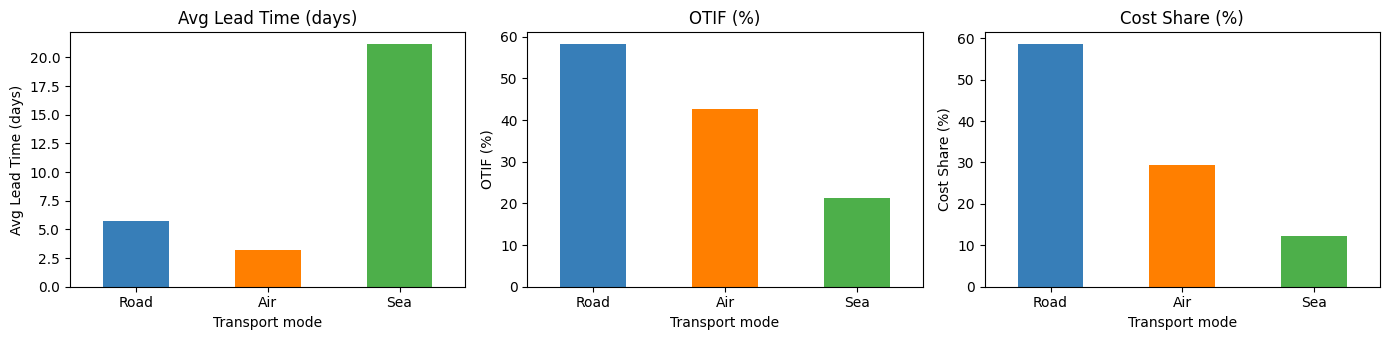

In [4]:
by_mode = summarize(baseline)[1].reindex(["Road", "Air", "Sea"])
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, metric in zip(axes, ["Avg Lead Time (days)", "OTIF (%)", "Cost Share (%)"]):
    by_mode[metric].plot.bar(ax=ax, color=["#377eb8", "#ff7f00", "#4daf4a"])
    ax.set_title(metric); ax.set_ylabel(metric); ax.set_xlabel("Transport mode")
    ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()  # <-- OBSERVE OUTPUT

**THINK:** Which mode is fastest? Which has the highest simplified OTIF? Which has the largest cost share? Explain why these need not be the same mode.

**Solution:** Compare the per-mode table. SLAs differ by mode; cost share also depends on shipment count.

## Experiments
Complete **Experiments 1–5 in order**. Each experiment starts independently from `baseline`, so changes do not accumulate across experiments. Finish its BEFORE / CHANGE / AFTER / THINK steps before moving to the next experiment.

### Experiment 1 — Mode mix
**Business question:** Does replacing some Road probability with Air change speed and cost?

**BEFORE:** Road/Air/Sea probabilities = 60% / 15% / 25%.

**CHANGE:** Set AIR_SHARE from 0.15 to 0.40. Road automatically decreases from 0.60 to 0.35; Sea stays 0.25. These are sampling probabilities, not guaranteed realized shares. The seed holds distances and random shocks fixed; modes change for some IDs.

**AFTER:** Read the comparison table, including signed differences and units.

In [5]:
AIR_SHARE = 0.40  # <-- CHANGE HERE: 0.15 -> 0.40
shares = {"Road": 1 - AIR_SHARE - 0.25, "Air": AIR_SHARE, "Sea": 0.25}
mode_mix_after = simulate_shipments(shares=shares, seed=42)
compare(baseline, mode_mix_after, "Experiment 1 — Mode mix")  # <-- OBSERVE OUTPUT

Experiment 1 — Mode mix
AFTER — transport-mode KPIs


,BEFORE,AFTER,Difference (AFTER - BEFORE),Difference unit
KPI,,,,
Shipments,600.00,600.00,0.00,shipments
OTIF (%),46.67,41.33,-5.33,percentage points
Avg Lead Time (days),9.22,8.60,-0.62,days
Avg Cost (EUR),812.15,1009.38,197.24,EUR/shipment
Total Cost (EUR),487288.70,605630.42,118341.72,EUR


,Shipments,OTIF (%),Avg Lead Time (days),Avg Cost (EUR),Total Cost (EUR),Mode Share (%),Cost Share (%)
Transport_Mode,,,,,,,
Air,238,36.97,3.28,1595.00,379608.96,39.67,62.68
Road,212,60.38,5.72,786.22,166678.37,35.33,27.52
Sea,150,21.33,21.13,395.62,59343.09,25.00,9.80


**THINK**

1. How do lead time and average cost change?
2. Does OTIF move in the same direction as speed? Explain the mode-specific SLAs.
3. Why can realized mode shares differ from sampling probabilities?

**Solution**

**Verified outcome:** OTIF 46.67% → 41.33% (-5.33 percentage points); mean lead time 9.22 → 8.60 days; mean cost EUR 812.15 → 1009.38.

More Air replaces Road probability; Sea probability stays fixed. Mean speed and cost reflect the assigned mode parameters. OTIF also depends on each mode's SLA, so the fastest mode need not have the best on-time rate. Realized counts come from random sampling; probabilities are not quotas.

### Experiment 2 — Road SLA
**Business question:** Can reported service change without faster or slower deliveries?

**BEFORE:** Road SLA = 6 days.

**CHANGE:** Set ROAD_SLA_DAYS from 6 to 5. Keep actual lead times, shipment counts and costs fixed.

**AFTER:** Read the comparison table, including signed differences and units.

In [6]:
ROAD_SLA_DAYS = 5  # <-- CHANGE HERE: 6 -> 5 days
sla_after = change_road_sla(baseline, ROAD_SLA_DAYS)
compare(baseline, sla_after, "Experiment 2 — Road SLA")  # <-- OBSERVE OUTPUT

Experiment 2 — Road SLA
AFTER — transport-mode KPIs


,BEFORE,AFTER,Difference (AFTER - BEFORE),Difference unit
KPI,,,,
Shipments,600.00,600.00,0.00,shipments
OTIF (%),46.67,26.50,-20.17,percentage points
Avg Lead Time (days),9.22,9.22,0.00,days
Avg Cost (EUR),812.15,812.15,0.00,EUR/shipment
Total Cost (EUR),487288.70,487288.70,0.00,EUR


,Shipments,OTIF (%),Avg Lead Time (days),Avg Cost (EUR),Total Cost (EUR),Mode Share (%),Cost Share (%)
Transport_Mode,,,,,,,
Air,89,42.70,3.18,1605.90,142925.45,14.83,29.33
Road,361,24.65,5.77,789.53,285020.16,60.17,58.49
Sea,150,21.33,21.13,395.62,59343.09,25.00,12.18


**THINK**

1. How many percentage points does overall OTIF change?
2. What changes for Road specifically?
3. Did delivery speed change, or did the scoring threshold change?

**Solution**

**Verified outcome:** OTIF 46.67% → 26.50% (-20.17 percentage points); mean lead time 9.22 → 9.22 days; mean cost EUR 812.15 → 812.15.

Only the Road scoring deadline changes. Shipments with lead time greater than 5 and no greater than 6 days lose their on-time status. Physical delivery speed and cost are identical. Tightening an SLA cannot improve on-time rate on fixed data, but a decrease requires at least one threshold crossing.

### Experiment 3 — Cost volatility
**Business question:** Does ±20% variation mean costs rise by exactly 20%?

**BEFORE:** Added cost variation = 0%; initial simulated costs already differ.

**CHANGE:** Set COST_VOLATILITY from 0.00 to 0.20. Apply one independent uniform percentage shock per shipment using seed 202. Inspect the distribution of percentage changes as well as mean cost.

**AFTER:** Read the comparison table, including signed differences and units.

In [7]:
COST_VOLATILITY = 0.20  # <-- CHANGE HERE: 0.00 -> 0.20
cost_after = vary_cost(baseline, COST_VOLATILITY, seed=202)
compare(baseline, cost_after, "Experiment 3 — Cost volatility")  # <-- OBSERVE OUTPUT
show_cost_shocks(baseline, cost_after)

Experiment 3 — Cost volatility
AFTER — transport-mode KPIs


,BEFORE,AFTER,Difference (AFTER - BEFORE),Difference unit
KPI,,,,
Shipments,600.00,600.00,0.00,shipments
OTIF (%),46.67,46.67,0.00,percentage points
Avg Lead Time (days),9.22,9.22,0.00,days
Avg Cost (EUR),812.15,814.26,2.11,EUR/shipment
Total Cost (EUR),487288.70,488554.57,1265.87,EUR


,Shipments,OTIF (%),Avg Lead Time (days),Avg Cost (EUR),Total Cost (EUR),Mode Share (%),Cost Share (%)
Transport_Mode,,,,,,,
Air,89,42.70,3.18,1604.86,142832.17,14.83,29.24
Road,361,58.17,5.77,795.70,287248.99,60.17,58.80
Sea,150,21.33,21.13,389.82,58473.41,25.00,11.97


,Metric,Value
0,Mean shipment cost change (%),0.15
1,Std. dev. of shipment cost change (percentage points),11.23
2,Min shipment cost change (%),-19.99
3,Max shipment cost change (%),19.99


**THINK**

1. How does mean cost change in this fixed sample?
2. Does zero expected shock imply exactly zero sample change?
3. Why do lead time and OTIF stay unchanged?

**Solution**

**Verified outcome:** OTIF 46.67% → 46.67% (+0.00 percentage points); mean lead time 9.22 → 9.22 days; mean cost EUR 812.15 → 814.26.

Independent percentage shocks have expected value zero. This finite seeded sample need not average to zero, and cost-weighted changes differ from an unweighted mean percentage shock. Lead time, mode and SLA are unchanged. Percentage-shock variability is added; cross-sectional cost standard deviation is not guaranteed to increase in every finite sample.

### Experiment 4 — Lead-time cap
**Business question:** What does an artificial cap do to reported performance?

**BEFORE:** No effective cap: 60 days, the generator maximum.

**CHANGE:** Set LEADTIME_CAP_DAYS from 60 to 10. This clips simulated records; no operational improvement mechanism or extra cost is modeled. Raw lead times are retained in Original_LeadTime_days.

**AFTER:** Read the comparison table, including signed differences and units.

In [8]:
LEADTIME_CAP_DAYS = 10  # <-- CHANGE HERE: 60 -> 10 days
cap_after = cap_leadtime(baseline, LEADTIME_CAP_DAYS)
compare(baseline, cap_after, "Experiment 4 — Lead-time cap")  # <-- OBSERVE OUTPUT

Experiment 4 — Lead-time cap
AFTER — transport-mode KPIs


,BEFORE,AFTER,Difference (AFTER - BEFORE),Difference unit
KPI,,,,
Shipments,600.00,600.00,0.00,shipments
OTIF (%),46.67,66.33,19.67,percentage points
Avg Lead Time (days),9.22,6.44,-2.78,days
Avg Cost (EUR),812.15,812.15,0.00,EUR/shipment
Total Cost (EUR),487288.70,487288.70,0.00,EUR


,Shipments,OTIF (%),Avg Lead Time (days),Avg Cost (EUR),Total Cost (EUR),Mode Share (%),Cost Share (%)
Transport_Mode,,,,,,,
Air,89,42.70,3.18,1605.90,142925.45,14.83,29.33
Road,361,58.17,5.77,789.53,285020.16,60.17,58.49
Sea,150,100.00,10.00,395.62,59343.09,25.00,12.18


**THINK**

1. Which mode contributes to the OTIF change?
2. Why does a 10-day cap not guarantee every shipment meets its own SLA?
3. What evidence/resources would justify an actual delivery improvement?

**Solution**

**Verified outcome:** OTIF 46.67% → 66.33% (+19.67 percentage points); mean lead time 9.22 → 6.44 days; mean cost EUR 812.15 → 812.15.

Sea has SLA 20 days and many baseline lead times above 20. Capping those at 10 reclassifies them. Road and Air already have much shorter lead times but stricter SLAs, so some remain late. The operation edits synthetic outcomes without modeling resources, feasibility or extra cost; it is not evidence of a cost-free real improvement.

### Experiment 5 — Add Rail
**Business question:** How does adding shipments affect the portfolio summary?

**BEFORE:** 600 Road/Air/Sea shipments; no Rail rows.

**CHANGE:** Set RAIL_SHIPMENTS from 0 to 120. Rail rate = EUR 0.80/km, base lead time = 8 days, SLA = 10 days, seed 303. The original 600 remain; total becomes 720. This is added volume, not a modal substitution.

**AFTER:** Read the comparison table, including signed differences and units.

In [9]:
RAIL_SHIPMENTS = 120  # <-- CHANGE HERE: 0 -> 120
rail_after = add_rail(baseline, RAIL_SHIPMENTS, 0.80, 8.0, 10, seed=303)
compare(baseline, rail_after, "Experiment 5 — Add Rail")  # <-- OBSERVE OUTPUT

Experiment 5 — Add Rail
AFTER — transport-mode KPIs


,BEFORE,AFTER,Difference (AFTER - BEFORE),Difference unit
KPI,,,,
Shipments,600.00,720.00,120.00,shipments
OTIF (%),46.67,54.17,7.50,percentage points
Avg Lead Time (days),9.22,9.16,-0.07,days
Avg Cost (EUR),812.15,786.94,-25.21,EUR/shipment
Total Cost (EUR),487288.70,566594.12,79305.42,EUR


,Shipments,OTIF (%),Avg Lead Time (days),Avg Cost (EUR),Total Cost (EUR),Mode Share (%),Cost Share (%)
Transport_Mode,,,,,,,
Air,89,42.70,3.18,1605.90,142925.45,12.36,25.23
Rail,120,91.67,8.82,660.88,79305.42,16.67,14.00
Road,361,58.17,5.77,789.53,285020.16,50.14,50.30
Sea,150,21.33,21.13,395.62,59343.09,20.83,10.47


**THINK**

1. Are Rail mean cost and mean lead time between Road and Sea here?
2. Why does total spend rise even if Rail average cost is relatively low?
3. What would you keep fixed to test replacing Road with Rail fairly?

**Solution**

**Verified outcome:** OTIF 46.67% → 54.17% (+7.50 percentage points); mean lead time 9.22 → 9.16 days; mean cost EUR 812.15 → 786.94.

Rail has intermediate assumed rate and base lead time relative to Road and Sea. Inspect the realized per-mode averages to confirm this sample. Total cost rises because 120 positive-cost rows are added. This is a composition/volume comparison; a fixed-volume replacement experiment would be needed to estimate modal substitution effects.

## Final reflection
Explain one operational trade-off, one reporting-only change, and one limitation of this simulation.

**Solution:** Mode mix compares speed/cost under chosen synthetic assumptions. Changing SLA changes reported service without changing transport. A lead-time cap alone does not establish a feasible operational improvement.